# Raw Material Usage Analysis: Swati Industries

**Author:** Roopali | **Tools:** Python (pandas, matplotlib, seaborn), Excel PivotTables

> **Data note:** The dataset is **simulated**. It was built to mirror the structure of raw-material records at Swati Industries (Ludhiana, Punjab): 5 materials x 12 months. It does **not** contain real company figures. The purpose is to demonstrate the analysis workflow.

## Business question
Which raw materials drive the most cost, how does spending change across the year, and where could procurement be optimized?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set_theme(style="whitegrid")
MONTHS = ["January","February","March","April","May","June",
          "July","August","September","October","November","December"]

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("../data/swati_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (60, 6)


,product_id,material_name,quantity_used_kg,cost_per_kg_inr,production_month,total_cost_inr
0,P-001,Steel Pipes,2860.0,64.8,January,185328.0
1,P-002,Cast Iron,1480.0,45.4,January,67192.0
2,P-003,Stainless Steel,540.0,254.8,January,137592.0
3,P-004,Metal Sheets,980.0,80.9,January,79282.0
4,P-005,Zinc Coating,310.0,149.7,January,46407.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_id        60 non-null     str    
 1   material_name     60 non-null     str    
 2   quantity_used_kg  60 non-null     float64
 3   cost_per_kg_inr   60 non-null     float64
 4   production_month  60 non-null     str    
 5   total_cost_inr    60 non-null     float64
dtypes: float64(3), str(3)
memory usage: 2.9 KB


## 2. Data quality checks
The checks below confirm the data is usable before any analysis: no missing values, no duplicates, no negative quantities or prices, and `total_cost_inr` matches quantity x price.

In [4]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Rows with quantity <= 0:", int((df["quantity_used_kg"] <= 0).sum()))
print("Rows with price <= 0:", int((df["cost_per_kg_inr"] <= 0).sum()))
recalc = (df["quantity_used_kg"] * df["cost_per_kg_inr"]).round(2)
print("total_cost_inr matches quantity x price:", bool((recalc - df["total_cost_inr"]).abs().max() < 0.01))
print("Months covered:", df["production_month"].nunique(), "| Materials:", df["material_name"].nunique())

Missing values: 0
Duplicate rows: 0
Rows with quantity <= 0: 0
Rows with price <= 0: 0
total_cost_inr matches quantity x price: True
Months covered: 12 | Materials: 5


In [5]:
df.describe().round(1)

,quantity_used_kg,cost_per_kg_inr,total_cost_inr
count,60.0,60.0,60.0
mean,1570.3,121.4,135928.0
std,1207.7,77.8,75257.2
min,310.0,45.4,46407.0
25%,637.5,66.1,79014.0
50%,1145.0,82.0,106923.0
75%,2070.0,157.5,186140.0
max,5060.0,267.5,343068.0


## 3. Which materials drive cost?

In [6]:
by_material = (df.groupby("material_name")
                 .agg(total_qty_kg=("quantity_used_kg", "sum"),
                      total_cost_inr=("total_cost_inr", "sum"),
                      avg_price_per_kg=("cost_per_kg_inr", "mean"))
                 .sort_values("total_cost_inr", ascending=False))
by_material["cost_share_pct"] = by_material["total_cost_inr"] / by_material["total_cost_inr"].sum() * 100
by_material["volume_share_pct"] = by_material["total_qty_kg"] / by_material["total_qty_kg"].sum() * 100
by_material.round(1)

,total_qty_kg,total_cost_inr,avg_price_per_kg,cost_share_pct,volume_share_pct
material_name,,,,,
Steel Pipes,43430.0,2912274.0,66.9,35.7,46.1
Stainless Steel,8620.0,2224668.0,257.1,27.3,9.1
Metal Sheets,14850.0,1219349.0,81.8,15.0,15.8
Cast Iron,22450.0,1043697.0,46.4,12.8,23.8
Zinc Coating,4870.0,755692.0,154.6,9.3,5.2


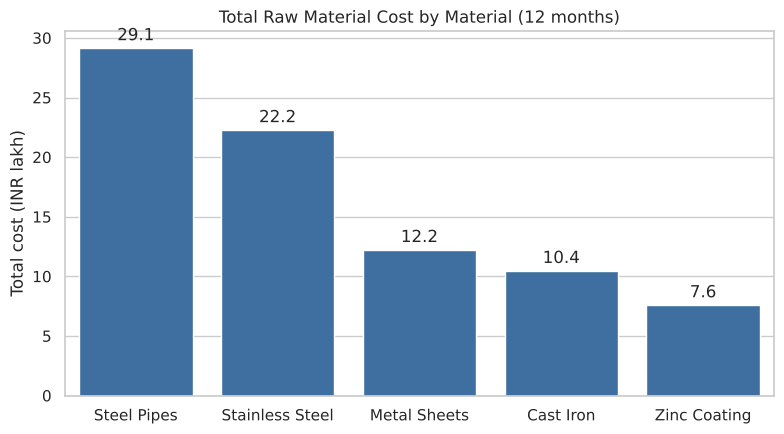

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = by_material.reset_index()
plot_df["cost_lakh"] = plot_df["total_cost_inr"] / 1e5
sns.barplot(x="material_name", y="cost_lakh", data=plot_df, color="#2F6FB0", ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_title("Total Raw Material Cost by Material (12 months)")
ax.set_xlabel("")
ax.set_ylabel("Total cost (INR lakh)")
plt.tight_layout()
plt.savefig("../charts/cost_by_material.png", dpi=150)
plt.show()

## 4. How does spending change across the year?

In [8]:
monthly = (df.groupby("production_month")["total_cost_inr"].sum()
             .reindex(MONTHS))
print("Lowest month: ", monthly.idxmin(), f"(INR {monthly.min():,.0f})")
print("Highest month:", monthly.idxmax(), f"(INR {monthly.max():,.0f})")
early = monthly.loc["January":"August"].mean()
late = monthly.loc["September":"December"].mean()
print(f"Avg monthly cost Jan-Aug: INR {early:,.0f}")
print(f"Avg monthly cost Sep-Dec: INR {late:,.0f}  ({(late/early-1)*100:+.0f}%)")
print(f"December vs January: {(monthly['December']/monthly['January']-1)*100:+.0f}%")

Lowest month:  January (INR 515,801)
Highest month: December (INR 973,981)
Avg monthly cost Jan-Aug: INR 591,501
Avg monthly cost Sep-Dec: INR 855,918  (+45%)
December vs January: +89%


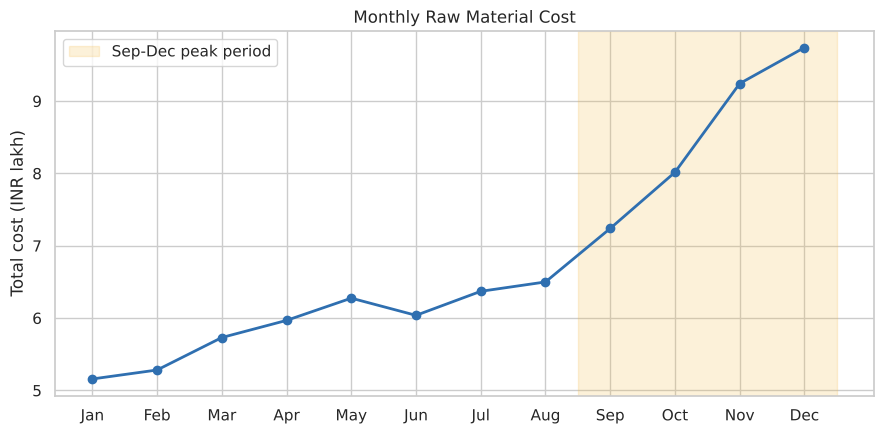

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(MONTHS, monthly.values / 1e5, marker="o", color="#2F6FB0", linewidth=2)
ax.axvspan(7.5, 11.5, color="#F4B942", alpha=0.2, label="Sep-Dec peak period")
ax.set_title("Monthly Raw Material Cost")
ax.set_ylabel("Total cost (INR lakh)")
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in MONTHS])
ax.legend()
plt.tight_layout()
plt.savefig("../charts/monthly_cost_trend.png", dpi=150)
plt.show()

In [10]:
# Which materials drive the Sep-Dec increase?
pivot = df.pivot_table(index="material_name", columns="production_month",
                       values="total_cost_inr", aggfunc="sum")[MONTHS]
rise = (pivot[["September","October","November","December"]].mean(axis=1)
        - pivot[MONTHS[:8]].mean(axis=1)).sort_values(ascending=False)
(rise / rise.sum() * 100).round(1).rename("share of the Sep-Dec increase (%)")

,share of the Sep-Dec increase (%)
material_name,
Steel Pipes,36.1
Stainless Steel,26.9
Metal Sheets,15.5
Cast Iron,12.1
Zinc Coating,9.3


## 5. Cost share vs volume share
A material that takes a bigger share of spend than of volume is expensive per kg. These are the first candidates for a pricing or alternatives review.

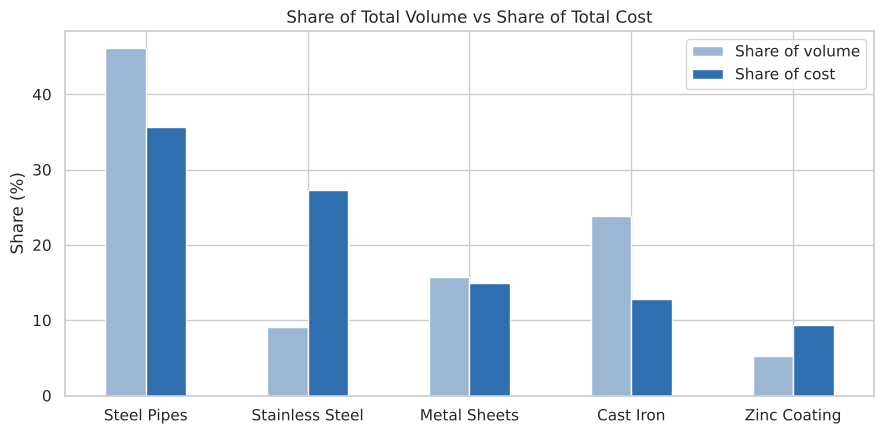

,volume_share_pct,cost_share_pct
material_name,,
Steel Pipes,46.1,35.7
Stainless Steel,9.1,27.3
Metal Sheets,15.8,15.0
Cast Iron,23.8,12.8
Zinc Coating,5.2,9.3


In [11]:
share = by_material[["volume_share_pct", "cost_share_pct"]].round(1)
fig, ax = plt.subplots(figsize=(9, 4.5))
share.plot(kind="bar", ax=ax, color=["#9BB7D4", "#2F6FB0"])
ax.set_title("Share of Total Volume vs Share of Total Cost")
ax.set_xlabel("")
ax.set_ylabel("Share (%)")
ax.set_xticklabels(share.index, rotation=0)
ax.legend(["Share of volume", "Share of cost"])
plt.tight_layout()
plt.savefig("../charts/volume_vs_cost_share.png", dpi=150)
plt.show()
share

## 6. Findings and recommendations

**Findings** (all figures from the simulated dataset above)
1. **Steel Pipes and Stainless Steel are the top two cost drivers**, together about 63% of total spend. Steel Pipes lead on volume; Stainless Steel is only 9% of volume but 27% of cost because of its high price per kg.
2. **Costs rise sharply late in the year.** January is the cheapest month and December the most expensive (+89%). Average monthly spend in Sep-Dec is about 45% above Jan-Aug.
3. **Zinc Coating and Stainless Steel are costly for their volume.** Zinc Coating is about 5% of volume but 9% of cost; Stainless Steel is 9% of volume but 27% of cost.

**Recommendations**
- **Negotiate bulk or contract pricing** for Steel Pipes and Stainless Steel, which are the largest share of spend.
- **Plan purchasing ahead of the Sep-Dec peak** by forecasting demand and buying earlier, to smooth cash flow and reduce exposure to price rises.
- **Review Zinc Coating and Stainless Steel usage** for alternatives or more efficient application, since they cost far more per kg than their share of volume.

**Next steps:** This analysis uses a simulated dataset, which let me demonstrate the full workflow (cleaning, aggregation, visualization, recommendations) without sharing company data. With real records, I would validate the seasonal pattern across multiple years, add supplier-level detail, and test whether price per kg trends upward over time.